## **¿ES BITCOIN ORO DIGITAL?**

-----------------------------------------------------------------------------------------------------------------------------------------------------

## **1.- INTRODUCCIÓN**

-----------------------------------------------------------------------------------------------------------------------------------------------------

**¿ES EL BITCOIN EL "ORO DIGITAL"? ¿ACTÚA COMO ACTIVO REFUGIO EN LAS CRISIS ECONÓMICAS?**
- Un activo refugio es aquel que mantiene su valor, o incluso sube, cuando los mercados caen. El referente clásico es el oro.

- En los últimos años se ha extendido la idea de que el bitcoin es el "oro digital" y en este proyecto analizaremos con datos la pregunta de si el Bitcoin es un activo refugio y se comporta como el oro ante los momentos de crisis financieras
- Nuestro análisis se centra en el periodo del 01 de enero de 2014 hasta 10 de noviembre de 2026

**SE ANALIZARÁ:**
    
- **Evolución del precio del bitcoin.** Comportamiento y evolución del precio del bitcoin para el periodo de análisis.
- **S&P 500:** identifica las crisis (días y periodos de caída de la bolsa).
- **Oro:** refugio con el que se compara el bitcoin.
- **Tipos de la Fed:** clasifican los periodos en fases de subida, bajada o tipos estables.

**CRISIS PREVISTAS PARA EL ANÁLISIS:** 

- 1.- 2015 - Crash bursátil chino. 
- 2.- 2016 - Brexit.
- 3.- 2018 - Endurecimiento de tipos de la FED.
- 4.- 2020 - Crisis del COVID. 
- 5.- 2022 - Inflación y subida de tipos.
- 6.- 2023 - Crisis bancaria de EE. UU.
- 7.- 2024 - Desplome del "carry trade" del yen.
- 8.- 2025 -	Choque arancelario global de EE. UU.
- 9.- 2026 -	Conflicto geopolítico con Irán y corrección de mercados.



### **HIPÓTESIS**

**Hipótesis general:** NO. El bitcoin no es un activo refugio, porque en épocas de crisis ha tenido mucha volatilidad y su valor se ha reducido.

- **Hipótesis 1:** en las crisis financieras desde 2014, el bitcoin cayó junto con la bolsa.
- **Hipótesis 2:** el bitcoin se comporta más como la renta variable (S&P 500) que como el oro.
- **Hipótesis 3:** el bitcoin cae cuando la Reserva Federal (FED) sube los tipos de interés y sube cuando los baja, igual que la bolsa.

-----------------------------------------------------------------------------------------------------------------------------------------------------

## **2.- FUENTES DE DATOS Y LIMPIEZA**

------------------------------------------------------------------------------------------------------------------------------------------------------

Para nuestro análisis se han utilizado 4 fuentes de datos para aportar información a nuestras conclusiones:




| Dato | Fuente | Frecuencia | Periodo del fichero |
|---|---|---|---|
| Bitcoin (BTC/USD) | [Investing.com](https://es.investing.com/crypto/bitcoin) | Diaria | 01/11/2013 – 10/11/2026 |
| S&P 500 | [Investing.com](https://es.investing.com/indices/us-spx-500) | Diaria | 12/01/2010 – 10/11/2026 |
| Oro (XAU/USD) | [Investing.com](https://es.investing.com/currencies/xau-usd) | Diaria | 12/01/2010 – 10/11/2026 |
| Tipos de interés de la FED (FEDFUNDS) | [FRED – Reserva Federal de San Luis](https://fred.stlouisfed.org/series/fedfunds) | Mensual | 01/2010 – 10/2026 |

Librerías utilizadas: **NumPy** y **Pandas** para la limpieza y el análisis, y **Matplotlib** y **Seaborn** para los gráficos.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Revisamos las tablas, buscamos valores nulos, eliminamos columnas innecesarias, y seleccionamos los índices y columnas iguales para nuestro análisis.

**2.1.- Limpieza de los datos históricos del Bitcoin**

Fuente: https://es.investing.com/crypto/bitcoin

Los CSV de Investing.com vienen en formato español: punto en los miles, coma en los decimales y fecha dd-mm-aaaa.

- Se carga el fichero indicando ese formato. La fecha se lee como texto para que el punto no se interprete como separador de miles.
- Se convierte la fecha a tipo fecha, se usa como índice y se ordena de la más antigua a la más reciente.
- Se convierte la columna `% var.` en número.
- Se eliminan las columnas Máximo, Mínimo y Vol., que no son necesarias para el análisis.

In [3]:
# Importamos el fichero de los datos históricos del bitcoin y creamos un dataframe con formato de miles con ".", decimales con "," y fecha como str.

df_btc = pd.read_csv(
    "data/Datos históricos del Bitcoin.csv",
    thousands=".",
    decimal=",",
    dtype={"Fecha": str}
)

In [4]:
# Ponemos las fechas como indices y ordenamos
df_btc["Fecha"] = pd.to_datetime(df_btc["Fecha"], format="%d.%m.%Y")
df_btc = df_btc.set_index("Fecha")
df_btc = df_btc.sort_index()


In [5]:
# Se elimina el símbolo %, se cambia la "," por el "." de la columna var. y se convierte en un float.
df_btc["% var."] = df_btc["% var."].str.replace("%", "").str.replace(",", ".").astype(float)

In [6]:
# Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.
df_btc = df_btc.drop(columns=["Máximo", "Mínimo", "Vol."])
df_btc = df_btc.sort_index()


In [7]:
# PRIMERA TABLA LIMPIA DE BITCOIN
df_btc.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4758 entries, 2013-11-01 to 2026-11-10
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Último    4758 non-null   float64
 1   Apertura  4758 non-null   float64
 2   % var.    4758 non-null   float64
dtypes: float64(3)
memory usage: 148.7 KB


----------------------------------

Fuente: https://es.investing.com/indices/us-spx-500

- Importamos el fichero de los datos históricos del S&P 500 y creamos un dataframe con formato español de miles con ".", decimales con "," y fecha como str.
- Ponemos las fechas como indices y ordenamos
- Se elimina el símbolo %, se cambia la "," por el "." de la columna var. y se convierte en un float.
- Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.

In [8]:
# Importamos el fichero de los datos históricos del S&P 500 y creamos un dataframe con formato de miles con ".", decimales con "," y fecha como str.

df_sp500 = pd.read_csv(
    "data/Datos históricos del S&P 500.csv",
    thousands=".",
    decimal=",",
    dtype={"Fecha": str}
)

In [9]:
# La fecha va como índice y con su formato correspondiente
df_sp500["Fecha"] = pd.to_datetime(df_sp500["Fecha"], format="%d.%m.%Y")
df_sp500 = df_sp500.set_index("Fecha")
df_sp500 = df_sp500.sort_index()

In [10]:
# Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.
df_sp500 = df_sp500.drop(columns=["Máximo", "Mínimo", "Vol."])
df_sp500 = df_sp500.sort_index()


In [11]:
# Se elimina el símbolo %, se cambia la "," por el "." de la columna var. y se convierte en un float.
df_sp500["% var."] = df_sp500["% var."].str.replace("%", "").str.replace(",", ".").astype(float)

In [12]:
# PRIMERA TABLA LIMPIA DEL S&P 500
df_sp500.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4234 entries, 2010-01-12 to 2026-11-10
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Último    4234 non-null   float64
 1   Apertura  4234 non-null   float64
 2   % var.    4234 non-null   float64
dtypes: float64(3)
memory usage: 132.3 KB


**2.3.- Limpieza de los datos del Oro**

Fuente: https://es.investing.com/currencies/xau-usd

- Importamos el fichero de los datos históricos del oro y creamos un dataframe con formato español de miles con ".", decimales con "," y fecha como str.
- Ponemos las fechas como indices y ordenamos
- Se elimina el símbolo %, se cambia la "," por el "." de la columna var. y se convierte en un float.
- Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.

In [13]:
df_oro = pd.read_csv(
    "data/Datos históricos XAU_USD.csv",
    thousands=".",
    decimal=",",
    dtype={"Fecha": str}
)

In [14]:
# La fecha va como índice y con su formato correspondiente
df_oro["Fecha"] = pd.to_datetime(df_oro["Fecha"], format="%d.%m.%Y")
df_oro = df_oro.set_index("Fecha")
df_oro = df_oro.sort_index()

In [15]:
# Se elimina el símbolo %, se cambia la "," por el "." de la columna var. y se convierte en un float.
df_oro["% var."] = df_oro["% var."].str.replace("%", "").str.replace(",", ".").astype(float)

In [16]:
# Se eliminan Máximo, Mínimo y Vol. por no ser necesarias para el análisis.
df_oro = df_oro.drop(columns=["Máximo", "Mínimo", "Vol."])
df_oro = df_oro.sort_index()


In [17]:
# PRIMERA TABLA LIMPIA DEL ORO
df_oro.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4340 entries, 2010-01-12 to 2026-11-10
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Último    4340 non-null   float64
 1   Apertura  4340 non-null   float64
 2   % var.    4340 non-null   float64
dtypes: float64(3)
memory usage: 135.6 KB


**2.4.-Limpieza de datos de los tipos de interés de la FED**

Fuente: https://fred.stlouisfed.org/series/fedfunds

- Importamos el fichero de los datos históricos de la FED, los números ya vienen en formato estándar y creamos un dataframe, cambiamos el nombre de la columna "observation_date" a "Fecha" y la ponemos como índice para que coincida con el resto de tablas.

In [18]:
df_fed = pd.read_csv("data/FEDFUNDS.csv", dtype={"observation_date": str})
df_fed = df_fed.rename(columns={"observation_date": "Fecha"})

In [19]:
# PRIMERA TABLA LIMPIA FED
df_fed.info()

<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Fecha     202 non-null    str    
 1   FEDFUNDS  202 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.3 KB


**2.5.- Tablas con las mismas fechas en el índice: Bitcoin cotiza todos los dias, el S&P 500 y Oro no cotizan los fines de semana y festivos,  y los datos de la FED son mensuales.**

- Fechas comunes: solo los días que existen en BTC, S&P 500 y oro, a partir del 01-01-2014.
- El Bitcoin cotiza todos los dias pero el S&P 500 y el Oro no, cierra fines de semana y festivos.
- La FED es mensual (día 1 de cada mes): su tipo se mantiene todo el mes, así que se rellena hacia delante (ffill) en esas fechas.


In [20]:
# Fechas comunes: solo los días que existen en BTC, S&P 500 y oro, a partir del 01-01-2014.
# El Bitcoin cotiza todos los dias pero el S&P 500 y el Oro no, cierra fines de semana y festivos.
# La FED es mensual (día 1 de cada mes): su tipo se mantiene todo el mes, así que se rellena hacia delante (ffill) en esas fechas.

df_fed["Fecha"] = pd.to_datetime(df_fed["Fecha"], format="%Y-%m-%d")
df_fed = df_fed.set_index("Fecha").sort_index()

fechas_comunes = df_btc.index.intersection(df_sp500.index).intersection(df_oro.index)
fechas_comunes = fechas_comunes[fechas_comunes >= "2014-01-01"]

df_btc = df_btc.loc[fechas_comunes]
df_sp500 = df_sp500.loc[fechas_comunes]
df_oro = df_oro.loc[fechas_comunes]
df_fed = df_fed.reindex(df_fed.index.union(fechas_comunes)).ffill().loc[fechas_comunes]



In [21]:
# COMPROBAMOS QUE LAS FECHAS DE LAS TABLAS COINCIDEN CON NUESTRO PERIODO DE ANALISIS Y CON LAS FECHAS DE DATOS COINCIDENTES
for nombre, df in [("BTC", df_btc), ("S&P 500", df_sp500), ("Oro", df_oro), ("FED", df_fed)]:
    print(nombre, df.shape, df.index.min().date(), "->", df.index.max().date())

BTC (3226, 3) 2014-01-02 -> 2026-11-10
S&P 500 (3226, 3) 2014-01-02 -> 2026-11-10
Oro (3226, 3) 2014-01-02 -> 2026-11-10
FED (3226, 1) 2014-01-02 -> 2026-11-10


In [22]:
df_btc

,Último,Apertura,% var.
Fecha,,,
2014-01-02,856.9,815.9,5.02
2014-01-03,884.3,856.9,3.19
2014-01-06,1012.7,1014.7,-0.21
2014-01-07,879.9,1012.7,-13.11
2014-01-08,938.8,879.9,6.70
...,...,...,...
2026-11-04,80476.7,77427.3,3.95
2026-11-05,76061.6,80487.1,-5.49
2026-11-06,75823.7,76063.5,-0.31


In [23]:
df_sp500

,Último,Apertura,% var.
Fecha,,,
2014-01-02,1832.00,1845.90,-0.89
2014-01-03,1831.40,1833.20,-0.03
2014-01-06,1826.80,1832.30,-0.25
2014-01-07,1837.90,1828.70,0.61
2014-01-08,1837.50,1837.90,-0.02
...,...,...,...
2026-11-04,7688.62,7635.81,1.58
2026-11-05,7353.73,7678.72,-4.36
2026-11-06,7376.86,7377.65,0.31


In [24]:
df_oro

,Último,Apertura,% var.
Fecha,,,
2014-01-02,1224.38,1205.09,1.60
2014-01-03,1236.90,1224.38,1.02
2014-01-06,1238.10,1236.90,0.10
2014-01-07,1232.12,1238.10,-0.48
2014-01-08,1225.97,1232.12,-0.50
...,...,...,...
2026-11-04,4060.02,3928.48,3.35
2026-11-05,4087.71,4059.93,0.68
2026-11-06,4066.63,4087.48,-0.52


**2.6.- Variación diaria corregida**

La columna % var. del bitcoin la calcula Investing.com respecto al **día natural anterior**, incluidos sábados y domingos. Al quedarnos solo con los días en que cotiza la bolsa, el lunes del bitcoin compararía con el domingo y no con el viernes.

Por eso se recalcula la variación diaria de los tres activos sobre las fechas comunes: cada cierre se compara con el cierre anterior de la tabla.

In [25]:
var_diaria = pd.DataFrame(index=df_btc.index[1:])

for nombre, tabla in [("bitcoin", df_btc), ("sp500", df_sp500), ("oro", df_oro)]:
    cierre = tabla["Último"].values
    var_diaria[nombre] = (cierre[1:] - cierre[:-1]) / cierre[:-1] * 100

var_diaria.head()

,bitcoin,sp500,oro
Fecha,,,
2014-01-03,3.197573,-0.032751,1.022558
2014-01-06,14.519959,-0.251174,0.097017
2014-01-07,-13.113459,0.607620,-0.482998
2014-01-08,6.693942,-0.021764,-0.499140
2014-01-09,-0.191734,0.032653,0.170477


**2.7.- Se crea la tabla de las crisis financieras a analizar**

Cada crisis va **desde el máximo del S&P 500 antes de la caída hasta el mínimo posterior**, según las fechas de cada episodio
- Tabla de crisis: nombre, fecha de inicio y fecha de fin.

In [26]:
# Tabla de crisis: nombre, fecha de inicio y fecha de fin.

crisis = pd.DataFrame({
    "crisis": ["Crash bursátil chino", "Brexit", "Subida de tipos FED 2018", "COVID",
               "Inflación y subida de tipos", "Crisis bancaria EE. UU.", "Carry trade del yen",
               "Aranceles EE. UU.", "Conflicto con Irán"],
    "inicio": ["2015-08-17", "2016-06-23", "2018-09-20", "2020-02-19",
               "2022-01-03", "2023-03-08", "2024-07-16", "2025-02-19", "2026-02-01"],
    "fin":    ["2015-08-25", "2016-06-27", "2018-12-24", "2020-03-23",
               "2022-10-12", "2023-03-13", "2024-08-05", "2025-04-08", "2026-04-04"]
})

crisis["inicio"] = pd.to_datetime(crisis["inicio"])
crisis["fin"] = pd.to_datetime(crisis["fin"])


In [27]:
# TABLA CRISIS CREADA
crisis

,crisis,inicio,fin
0,Crash bursátil chino,2015-08-17,2015-08-25
1,Brexit,2016-06-23,2016-06-27
2,Subida de tipos FED 2018,2018-09-20,2018-12-24
3,COVID,2020-02-19,2020-03-23
4,Inflación y subida de tipos,2022-01-03,2022-10-12
5,Crisis bancaria EE. UU.,2023-03-08,2023-03-13
6,Carry trade del yen,2024-07-16,2024-08-05
7,Aranceles EE. UU.,2025-02-19,2025-04-08
8,Conflicto con Irán,2026-02-01,2026-04-04


-----------------------------------------------------------------------------------------------------------------------------------------------------

## **3.- ANÁLISIS Y VISUALIZACIONES DE LAS HIPÓTESIS**

-----------------------------------------------------------------------------------------------------------------------------------------------------

Cada hipótesis sigue la misma estructura: cálculo → gráficos → conclusión.

**3.1.-HIPÓTESIS 1: En las crisis financieras desde el 2014 el Bitcoin cayó junto a la bolsa**

- Comportamiento del Bitcoin en los periodos de crisis desde 2014
- Variación % del Bitcoin en los periodos de crisis desde 2014

- Comportamiento del Oro en los periodos de crisis desde 2014.
   
- Variación % del Oro en los periodos de crisis desde 2014
- Comportamiento del S&P 500 en los periodos de crisis desde 2014.
- Variación % del S&P 500 en los periodos de crisis desde 2014.
- Comparación de la variación (%) de cada activo en cada crisis 

**¿Cómo se comportó el bitcoin en las crisis?**

- Comportamiento del Bitcoin en los periodos de crisis desde 2014
    - Incluir columna en la tabla de bitcoin con los periodos de las crisis
    - Sacar la variación % del bitcoin en los periodos de crisis.

In [28]:
# Hacemos copia de la tabla limpia de bitcoin e incluimos con una columna que indicará la crisis de cada día.
df_btc_h1 = df_btc.copy()
df_btc_h1["crisis"] = "Sin crisis"
df_btc_h1

,Último,Apertura,% var.,crisis
Fecha,,,,
2014-01-02,856.9,815.9,5.02,Sin crisis
2014-01-03,884.3,856.9,3.19,Sin crisis
2014-01-06,1012.7,1014.7,-0.21,Sin crisis
2014-01-07,879.9,1012.7,-13.11,Sin crisis
2014-01-08,938.8,879.9,6.70,Sin crisis
...,...,...,...,...
2026-11-04,80476.7,77427.3,3.95,Sin crisis
2026-11-05,76061.6,80487.1,-5.49,Sin crisis
2026-11-06,75823.7,76063.5,-0.31,Sin crisis


In [29]:
# Se recorre la tabla de crisis y se marcan los días que caen entre su inicio y su fin.
for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]
    df_btc_h1.loc[inicio:fin, "crisis"] = nombre

In [30]:
# Precio de cierre del primer y del último día de cada crisis, y variación entre ambos.

tabla_btc = df_btc_h1[df_btc_h1["crisis"] != "Sin crisis"].groupby("crisis").agg(
    precio_inicio=("Último", "first"),
    precio_fin=("Último", "last")
)
tabla_btc["variacion_%"] = (tabla_btc["precio_fin"] - tabla_btc["precio_inicio"]) / tabla_btc["precio_inicio"] * 100
tabla_btc = tabla_btc.reindex(crisis["crisis"])
tabla_btc

,precio_inicio,precio_fin,variacion_%
crisis,,,
Crash bursátil chino,257.1,220.5,-14.235706
Brexit,620.8,644.7,3.849871
Subida de tipos FED 2018,6489.2,4026.1,-37.956913
COVID,9609.4,6468.9,-32.681541
Inflación y subida de tipos,46430.2,19154.8,-58.744955
Crisis bancaria EE. UU.,21710.8,24114.4,11.070988
Carry trade del yen,65049.7,53979.0,-17.018833
Aranceles EE. UU.,96644.8,76312.5,-21.038173
Conflicto con Irán,78720.6,66898.3,-15.018051


Gráfico 1.1.- Evolución del precio del Bitcoin en las crisis financieras 2014 -2026.

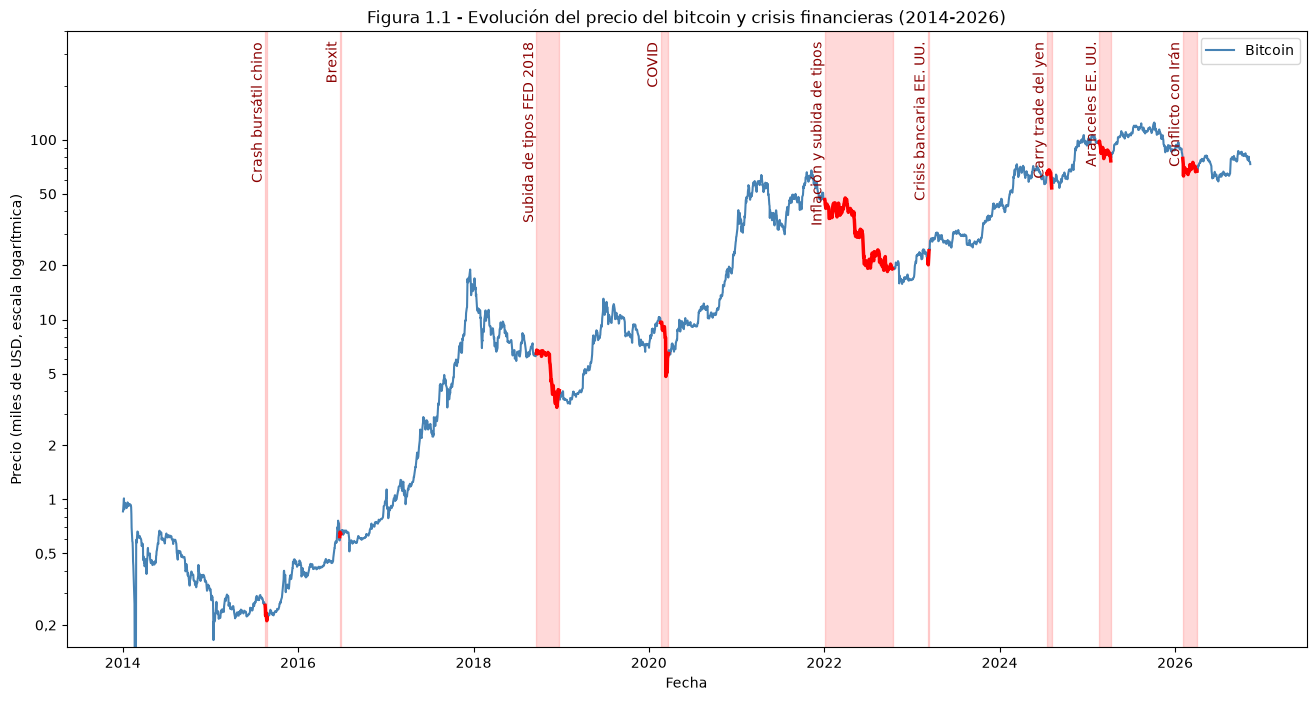

In [31]:
# Figura 1.1: evolución del precio del bitcoin (en miles de USD) con los periodos de crisis marcados.

btc_miles = df_btc["Último"] / 1000

plt.figure(figsize=(16, 8))

# Línea completa del precio
sns.lineplot(x=btc_miles.index, y=btc_miles, color="steelblue", label="Bitcoin")

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]

    # Franja sombreada del periodo de crisis
    plt.axvspan(inicio, fin, color="red", alpha=0.15)

    # Tramo del precio durante la crisis, en rojo
    tramo = btc_miles.loc[inicio:fin]
    sns.lineplot(x=tramo.index, y=tramo, color="red", linewidth=2.5)

    # Nombre de la crisis, en vertical en la parte superior
    plt.text(inicio, 350, nombre, rotation=90, va="top", ha="right", color="darkred", fontsize=10)

plt.yscale("log")
plt.ylim(0.15, 400)
plt.yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100],
           ["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])

plt.title("Figura 1.1 - Evolución del precio del bitcoin y crisis financieras (2014-2026)")
plt.xlabel("Fecha")
plt.ylabel("Precio (miles de USD, escala logarítmica)")
plt.show()

**¿Cómo se comportó el oro, el activo refugio por excelencia, en esos mismos momentos?**

- Comportamiento del Oro en los periodos de crisis desde 2014.
    - Incluir columna en la tabla del Oro con los periodos de las crisis
    - Sacar la variación % del Oro en los periodos de crisis.

In [32]:
df_oro_h1 = df_oro.copy()
df_oro_h1["crisis"] = "Sin crisis"

In [33]:
for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]
    df_oro_h1.loc[inicio:fin, "crisis"] = nombre

df_oro_h1["crisis"].value_counts()

crisis
Sin crisis                     2836
Inflación y subida de tipos     194
Subida de tipos FED 2018         66
Conflicto con Irán               43
Aranceles EE. UU.                35
COVID                            24
Carry trade del yen              14
Crash bursátil chino              7
Crisis bancaria EE. UU.           4
Brexit                            3
Name: count, dtype: int64

In [34]:
# Variación del Oro en los periodos de crisis

tabla_oro = df_oro_h1[df_oro_h1["crisis"] != "Sin crisis"].groupby("crisis").agg(
    precio_inicio=("Último", "first"),
    precio_fin=("Último", "last")
)
tabla_oro["variacion_%"] = (tabla_oro["precio_fin"] - tabla_oro["precio_inicio"]) / tabla_oro["precio_inicio"] * 100
tabla_oro = tabla_oro.reindex(crisis["crisis"])
tabla_oro

,precio_inicio,precio_fin,variacion_%
crisis,,,
Crash bursátil chino,1117.53,1140.65,2.068848
Brexit,1255.58,1324.40,5.481132
Subida de tipos FED 2018,1207.16,1269.03,5.125253
COVID,1611.69,1553.12,-3.634074
Inflación y subida de tipos,1801.19,1673.20,-7.105858
Crisis bancaria EE. UU.,1813.83,1913.63,5.502169
Carry trade del yen,2468.93,2409.89,-2.391319
Aranceles EE. UU.,2932.64,2983.78,1.743821
Conflicto con Irán,4666.27,4676.42,0.217518


Gráfico 1.2.- Evolución del precio del Oro en las crisis financieras 2014 -2026.

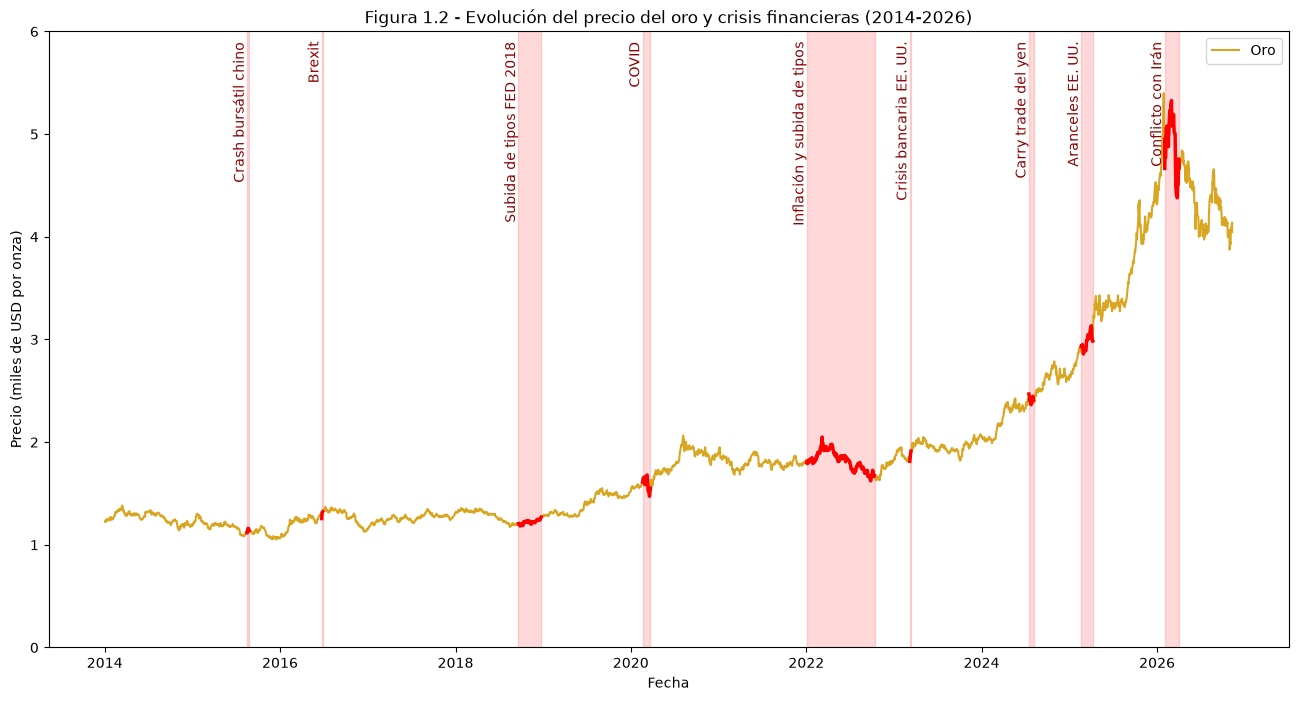

In [35]:
oro_miles = df_oro["Último"] / 1000

plt.figure(figsize=(16, 8))
sns.lineplot(x=oro_miles.index, y=oro_miles, color="goldenrod", label="Oro")

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]

    plt.axvspan(inicio, fin, color="red", alpha=0.15)
    tramo = oro_miles.loc[inicio:fin]
    sns.lineplot(x=tramo.index, y=tramo, color="red", linewidth=2.5)
    plt.text(inicio, 5.9, nombre, rotation=90, va="top", ha="right", color="darkred", fontsize=10)

plt.ylim(0, 6)
plt.title("Figura 1.2 - Evolución del precio del oro y crisis financieras (2014-2026)")
plt.xlabel("Fecha")
plt.ylabel("Precio (miles de USD por onza)")
plt.show()

**¿Y la renta variable (S&P 500)?**

- Comportamiento del S&P 500 en los periodos de crisis desde 2014
    - Incluir columna en la tabla de S&P 500 con los periodos de las crisis
    - Sacar la variación % del S&P 500 en los periodos de crisis.

In [36]:
# Copia de la tabla del S&P 500 para la H1, con una columna que indicará la crisis de cada día.
df_sp500_h1 = df_sp500.copy()
df_sp500_h1["crisis"] = "Sin crisis"

In [37]:
for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]
    df_sp500_h1.loc[inicio:fin, "crisis"] = nombre

df_sp500_h1["crisis"].value_counts()

crisis
Sin crisis                     2836
Inflación y subida de tipos     194
Subida de tipos FED 2018         66
Conflicto con Irán               43
Aranceles EE. UU.                35
COVID                            24
Carry trade del yen              14
Crash bursátil chino              7
Crisis bancaria EE. UU.           4
Brexit                            3
Name: count, dtype: int64

In [38]:
# Variación del S&P 500 en los periodos de crisis

tabla_sp500 = df_sp500_h1[df_sp500_h1["crisis"] != "Sin crisis"].groupby("crisis").agg(
    precio_inicio=("Último", "first"),
    precio_fin=("Último", "last")
)
tabla_sp500["variacion_%"] = (tabla_sp500["precio_fin"] - tabla_sp500["precio_inicio"]) / tabla_sp500["precio_inicio"] * 100
tabla_sp500 = tabla_sp500.reindex(crisis["crisis"])
tabla_sp500

,precio_inicio,precio_fin,variacion_%
crisis,,,
Crash bursátil chino,2102.40,1867.60,-11.168189
Brexit,2113.30,2000.50,-5.337624
Subida de tipos FED 2018,2930.80,2351.10,-19.779582
COVID,3386.20,2237.40,-33.925935
Inflación y subida de tipos,4796.60,3577.03,-25.425718
Crisis bancaria EE. UU.,3992.01,3855.76,-3.413068
Carry trade del yen,5667.20,5186.33,-8.485143
Aranceles EE. UU.,6144.15,4982.77,-18.902208
Conflicto con Irán,6976.44,6582.69,-5.643996


Gráfico 1.3.- Evolución del precio del S&P 500 en las crisis financieras 2014 -2026.

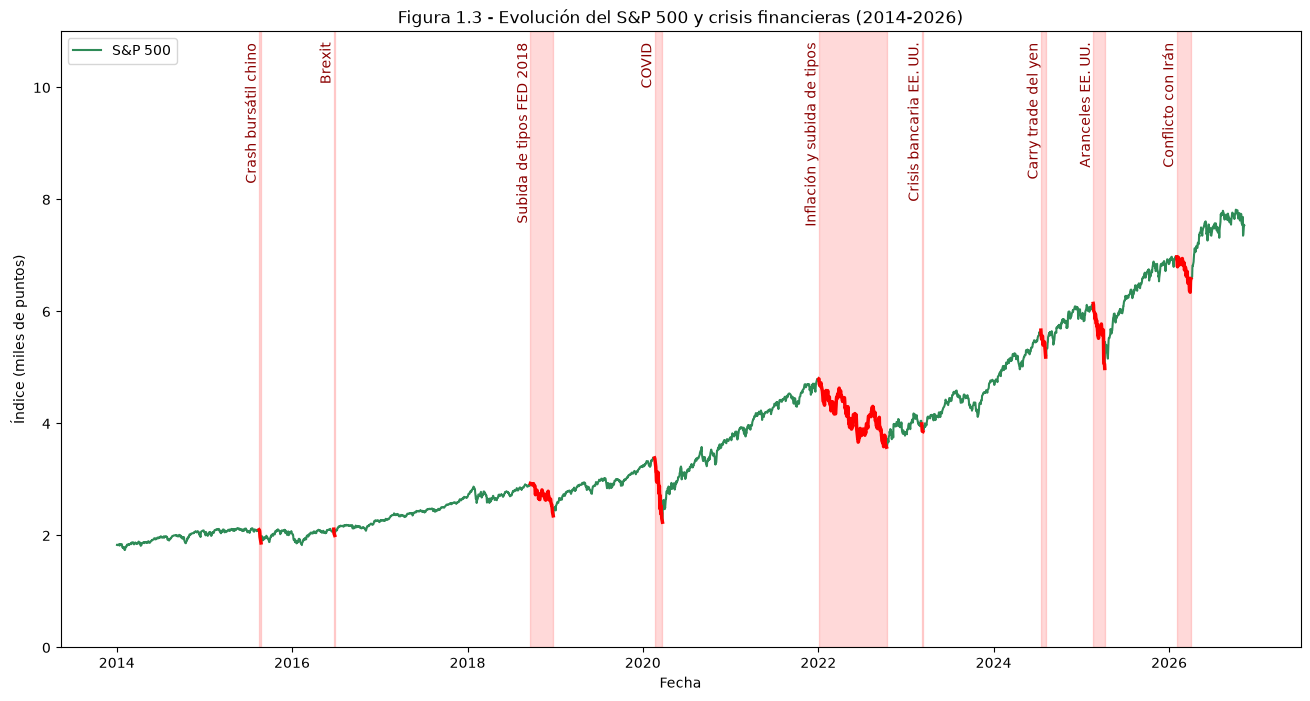

In [39]:
sp500_miles = df_sp500["Último"] / 1000

plt.figure(figsize=(16, 8))
sns.lineplot(x=sp500_miles.index, y=sp500_miles, color="seagreen", label="S&P 500")

for i in range(len(crisis)):
    inicio = crisis["inicio"][i]
    fin = crisis["fin"][i]
    nombre = crisis["crisis"][i]

    plt.axvspan(inicio, fin, color="red", alpha=0.15)
    tramo = sp500_miles.loc[inicio:fin]
    sns.lineplot(x=tramo.index, y=tramo, color="red", linewidth=2.5)
    plt.text(inicio, 10.8, nombre, rotation=90, va="top", ha="right", color="darkred", fontsize=10)

plt.ylim(0, 11)
plt.title("Figura 1.3 - Evolución del S&P 500 y crisis financieras (2014-2026)")
plt.xlabel("Fecha")
plt.ylabel("Índice (miles de puntos)")
plt.show()

**Comparación de la variación (%) de los tres activos en cada crisis**

In [40]:
# Tabla resumen H1: variación de cada activo en cada crisis (%).

resumen_h1 = pd.DataFrame({
    "bitcoin": tabla_btc["variacion_%"],
    "sp500": tabla_sp500["variacion_%"],
    "oro": tabla_oro["variacion_%"]
}).round(2)
resumen_h1

,bitcoin,sp500,oro
crisis,,,
Crash bursátil chino,-14.24,-11.17,2.07
Brexit,3.85,-5.34,5.48
Subida de tipos FED 2018,-37.96,-19.78,5.13
COVID,-32.68,-33.93,-3.63
Inflación y subida de tipos,-58.74,-25.43,-7.11
Crisis bancaria EE. UU.,11.07,-3.41,5.50
Carry trade del yen,-17.02,-8.49,-2.39
Aranceles EE. UU.,-21.04,-18.90,1.74
Conflicto con Irán,-15.02,-5.64,0.22


Gráfico 1.4.- Variación % del Bitcoin, Oro y S&P 500 en cada crisis financiera 2014 - 2026

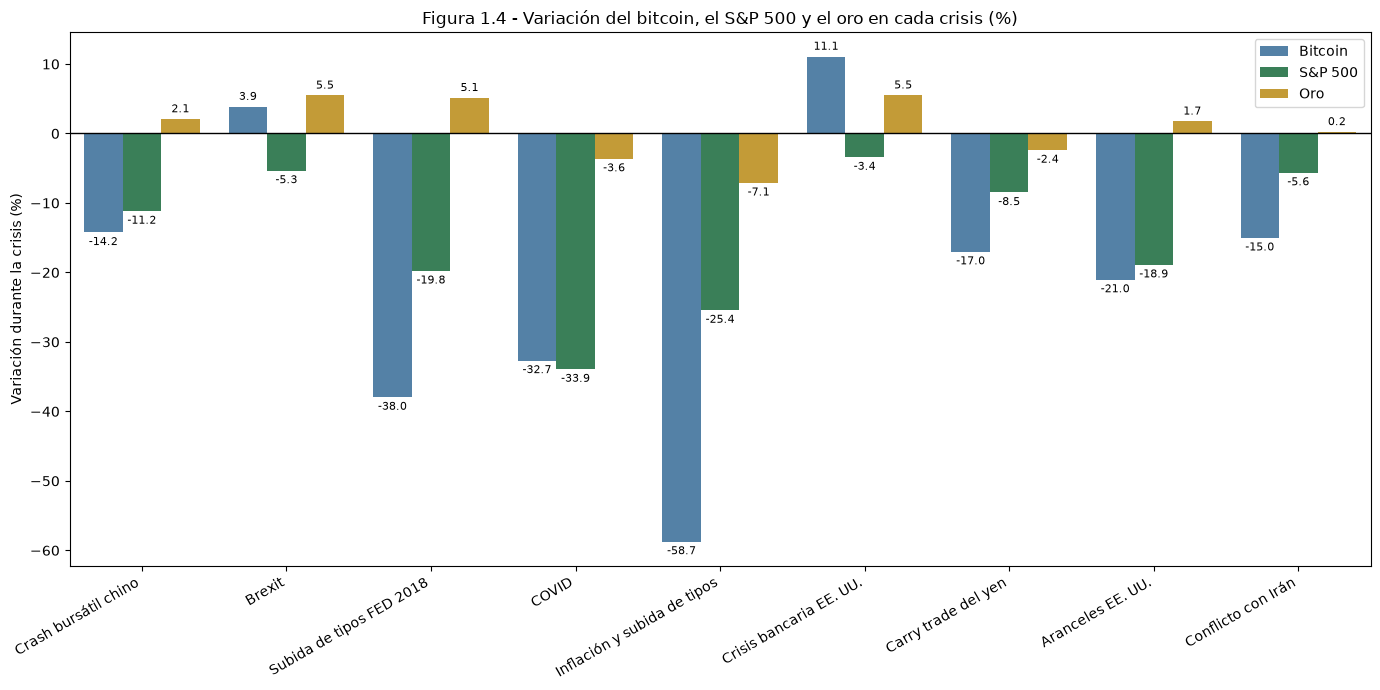

In [41]:
# Figura 1.4: variación (%) de cada activo en cada crisis (tabla resumen_h1).

# Formato largo para seaborn: una fila por crisis y activo.
h1_largo = (resumen_h1
            .rename(columns={"bitcoin": "Bitcoin", "sp500": "S&P 500", "oro": "Oro"})
            .rename_axis("crisis").reset_index()
            .melt(id_vars="crisis", var_name="activo", value_name="variacion"))

activos_h1 = ["Bitcoin", "S&P 500", "Oro"]

plt.figure(figsize=(14, 7))
ax = sns.barplot(data=h1_largo, x="crisis", y="variacion", hue="activo",
                 hue_order=activos_h1,
                 palette={"Bitcoin": "steelblue", "S&P 500": "seagreen", "Oro": "goldenrod"})

# Valor (%) encima/debajo de cada barra.
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f", padding=3, fontsize=8)

plt.axhline(0, color="black", linewidth=1)
plt.xticks(rotation=30, ha="right")
plt.title("Figura 1.4 - Variación del bitcoin, el S&P 500 y el oro en cada crisis (%)")
plt.ylabel("Variación durante la crisis (%)")
plt.xlabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()

**LA HIPÓTESIS 1 SE CONFIRMA:**

- En 7 de las 9 crisis el bitcoin cayó a la vez que el S&P 500, y de media cayó más que la bolsa (-20,2 % frente a -14,7 %).
- El oro solo cayó en 3 crisis y de media subió un 0,8 %.
- El bitcoin no actuó como refugio.

----------------------------------------------------------------------------------------------------------------------------------------------------

**3.2.- HIPÓTESIS 2: El Bitcoin se comporta más como renta variable (S&P 500) que como el oro (activo refugio).**

Se compara la evolución diaria del bitcoin con la del oro y la del S&P 500. Como sus precios tienen escalas muy distintas, cada activo usa su propio eje vertical, en escala logarítmica, para que los movimientos en porcentaje se vean del mismo tamaño.

- Comparación del comportamiento del Bitcoin vs Oro
- Comparación del comportamiento del Bitcoin vs S&P 500
- Comparación del comportamiento del Bitcoin vs Oro VS S&P 500
- Correlación Bitcoin-Oro-S&P 500

**¿Se han movido el bitcoin y el oro de la misma manera?**

In [42]:
# Precios de cierre de los tres activos en las fechas comunes.
precios = pd.DataFrame({
    "bitcoin": df_btc["Último"],
    "sp500": df_sp500["Último"],
    "oro": df_oro["Último"]
})

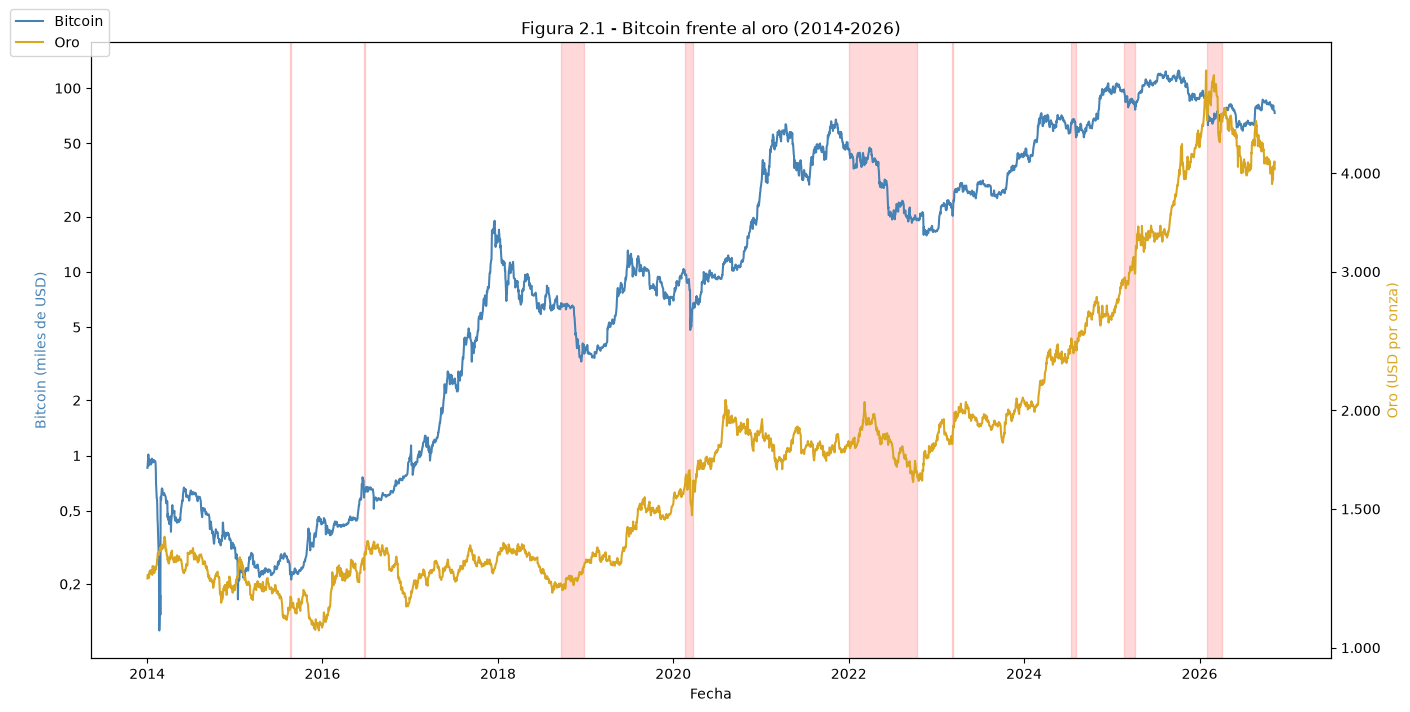

In [43]:
# Figura 2.1: bitcoin (eje izquierdo) frente al oro (eje derecho), datos diarios.

fig, ax1 = plt.subplots(figsize=(16, 8))

# Eje izquierdo: bitcoin en miles de USD
ax1.plot(df_btc.index, df_btc["Último"] / 1000, color="steelblue", linewidth=1.5, label="Bitcoin")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax1.set_yticklabels(["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])
ax1.minorticks_off()
ax1.set_ylabel("Bitcoin (miles de USD)", color="steelblue")

# Eje derecho: oro en USD por onza
ax2 = ax1.twinx()
ax2.plot(df_oro.index, df_oro["Último"], color="goldenrod", linewidth=1.5, label="Oro")
ax2.set_yscale("log")
ax2.set_yticks([1000, 1500, 2000, 3000, 4000])
ax2.set_yticklabels(["1.000", "1.500", "2.000", "3.000", "4.000"])
ax2.minorticks_off()
ax2.set_ylabel("Oro (USD por onza)", color="goldenrod")
ax2.grid(False)

# Periodos de crisis
for i in range(len(crisis)):
    ax1.axvspan(crisis["inicio"][i], crisis["fin"][i], color="red", alpha=0.15)

ax1.set_title("Figura 2.1 - Bitcoin frente al oro (2014-2026)")
ax1.set_xlabel("Fecha")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.show()

**¿Y el bitcoin y el S&P 500?**

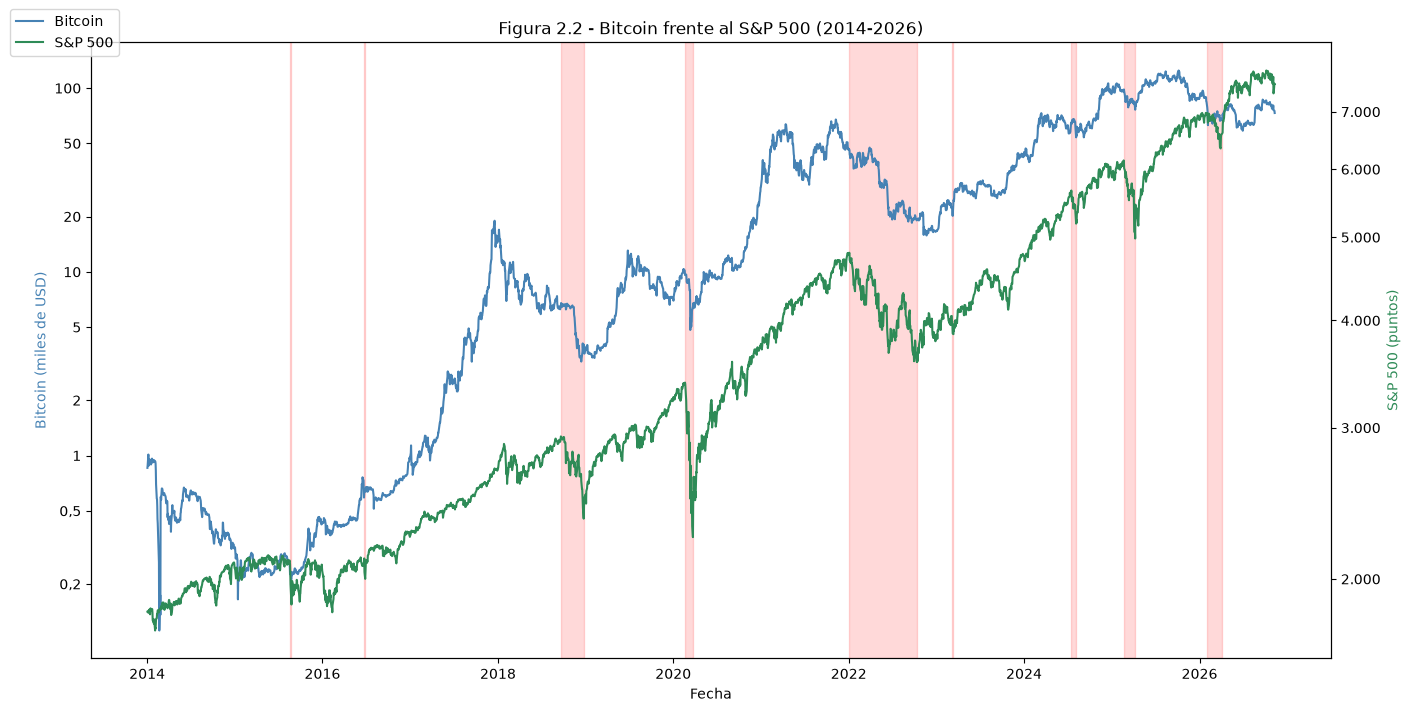

In [44]:
# Figura 2.2: bitcoin (eje izquierdo) frente al S&P 500 (eje derecho), datos diarios.

fig, ax1 = plt.subplots(figsize=(16, 8))

# Eje izquierdo: bitcoin en miles de USD
ax1.plot(df_btc.index, df_btc["Último"] / 1000, color="steelblue", linewidth=1.5, label="Bitcoin")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax1.set_yticklabels(["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])
ax1.minorticks_off()
ax1.set_ylabel("Bitcoin (miles de USD)", color="steelblue")

# Eje derecho: S&P 500 en puntos
ax2 = ax1.twinx()
ax2.plot(df_sp500.index, df_sp500["Último"], color="seagreen", linewidth=1.5, label="S&P 500")
ax2.set_yscale("log")
ax2.set_yticks([2000, 3000, 4000, 5000, 6000, 7000])
ax2.set_yticklabels(["2.000", "3.000", "4.000", "5.000", "6.000", "7.000"])
ax2.minorticks_off()
ax2.set_ylabel("S&P 500 (puntos)", color="seagreen")
ax2.grid(False)

# Periodos de crisis
for i in range(len(crisis)):
    ax1.axvspan(crisis["inicio"][i], crisis["fin"][i], color="red", alpha=0.15)

ax1.set_title("Figura 2.2 - Bitcoin frente al S&P 500 (2014-2026)")
ax1.set_xlabel("Fecha")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.show()

**Los tres activos juntos**

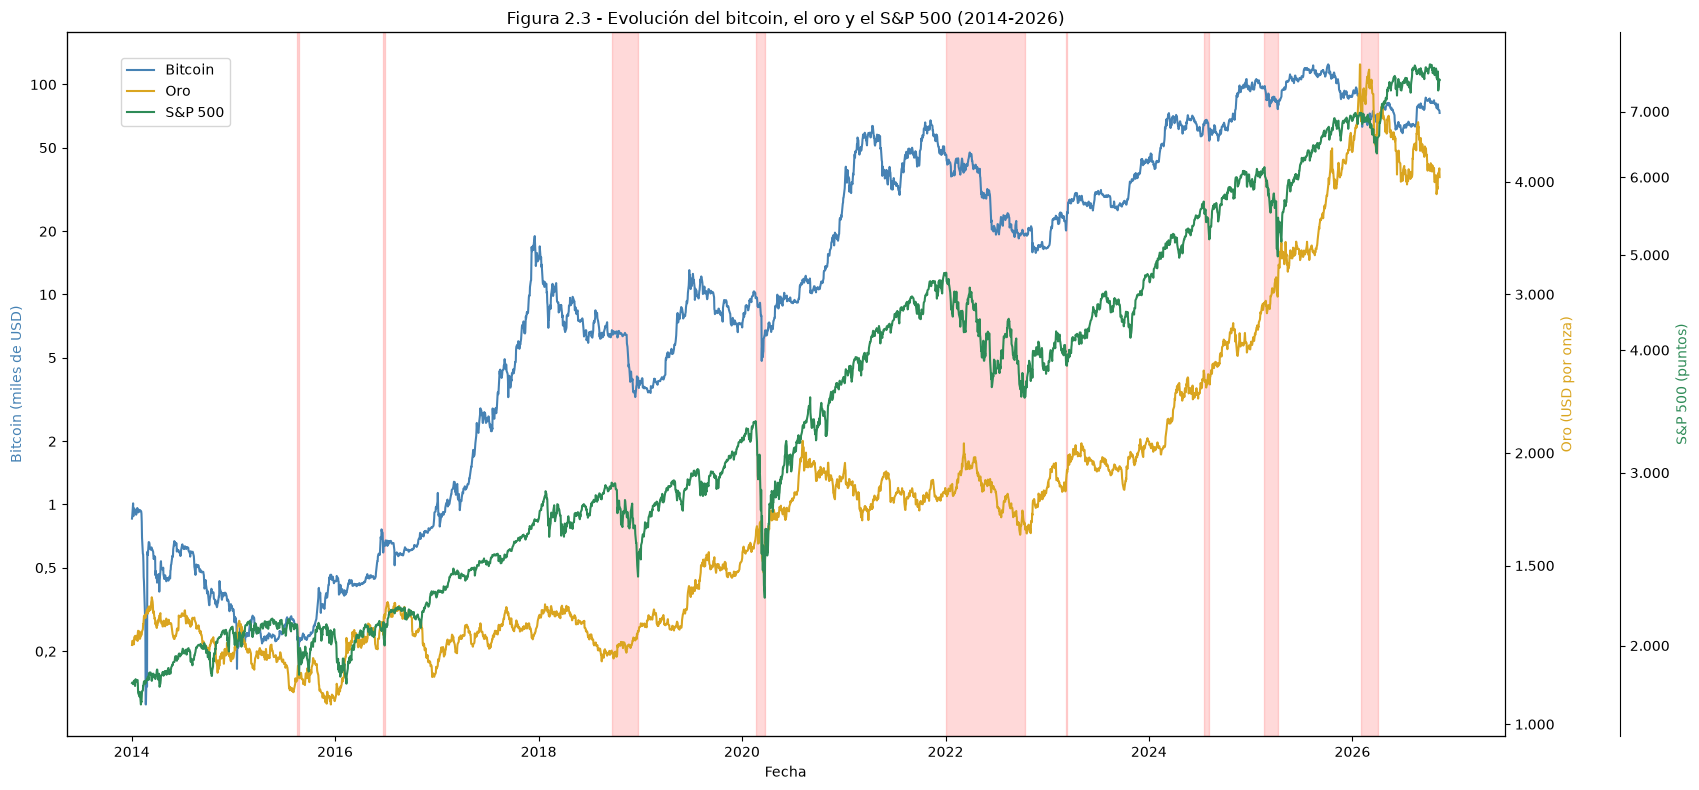

In [45]:
# Figura 2.3: evolución del bitcoin, el oro y el S&P 500 con tres ejes superpuestos (datos diarios).

fig, ax1 = plt.subplots(figsize=(17, 8))

# Eje 1 (izquierda): bitcoin en miles de USD
ax1.plot(df_btc.index, df_btc["Último"] / 1000, color="steelblue", linewidth=1.5, label="Bitcoin")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100])
ax1.set_yticklabels(["0,2", "0,5", "1", "2", "5", "10", "20", "50", "100"])
ax1.minorticks_off()
ax1.set_ylabel("Bitcoin (miles de USD)", color="steelblue")

# Eje 2 (derecha): oro en USD por onza
ax2 = ax1.twinx()
ax2.plot(df_oro.index, df_oro["Último"], color="goldenrod", linewidth=1.5, label="Oro")
ax2.set_yscale("log")
ax2.set_yticks([1000, 1500, 2000, 3000, 4000])
ax2.set_yticklabels(["1.000", "1.500", "2.000", "3.000", "4.000"])
ax2.minorticks_off()
ax2.set_ylabel("Oro (USD por onza)", color="goldenrod")
ax2.grid(False)

# Eje 3 (derecha, desplazado): S&P 500 en puntos
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("axes", 1.08))
ax3.plot(df_sp500.index, df_sp500["Último"], color="seagreen", linewidth=1.5, label="S&P 500")
ax3.set_yscale("log")
ax3.set_yticks([2000, 3000, 4000, 5000, 6000, 7000])
ax3.set_yticklabels(["2.000", "3.000", "4.000", "5.000", "6.000", "7.000"])
ax3.minorticks_off()
ax3.set_ylabel("S&P 500 (puntos)", color="seagreen")
ax3.grid(False)

# Periodos de crisis
for i in range(len(crisis)):
    ax1.axvspan(crisis["inicio"][i], crisis["fin"][i], color="red", alpha=0.15)

ax1.set_title("Figura 2.3 - Evolución del bitcoin, el oro y el S&P 500 (2014-2026)")
ax1.set_xlabel("Fecha")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.tight_layout()
plt.show()

**Correlación de las variaciones diarias**

La correlación va de -1 a 1: cerca de 1, los activos se mueven en la misma dirección; cerca de 0, no tienen relación; negativa, se mueven en sentido contrario. Se calcula con la variación diaria corregida (apartado 2.6), no con los precios: correlacionar precios daría valores altos solo porque los tres han subido a largo plazo.

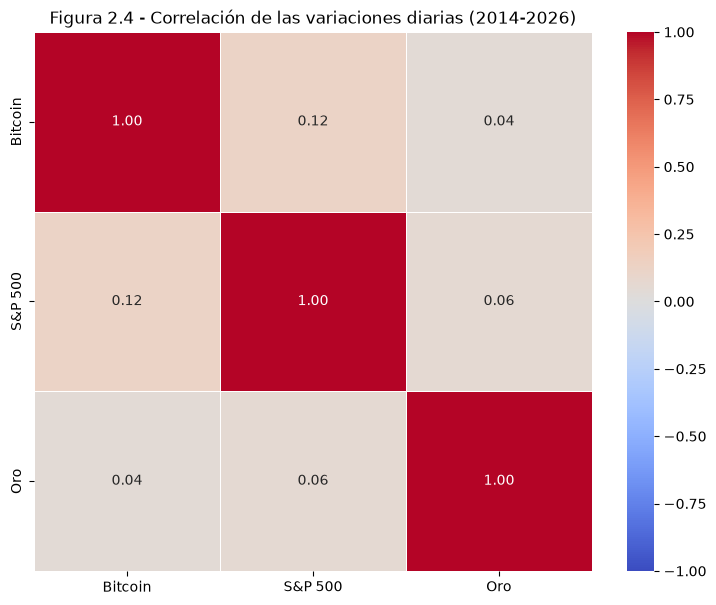

In [46]:
# Figura 2.4: matriz de correlación de las variaciones diarias de los tres activos.

correlaciones = var_diaria.rename(columns={"bitcoin": "Bitcoin", "sp500": "S&P 500", "oro": "Oro"}).corr()

f, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlaciones,
            annot=True,
            fmt=".2f",
            linewidths=.5,
            ax=ax,
            vmin=-1,
            vmax=1,
            cmap="coolwarm")

ax.set_title("Figura 2.4 - Correlación de las variaciones diarias (2014-2026)")
plt.show()

**Diferencia entre el bitcoin y cada activo en las crisis**

La tabla muestra la diferencia (en puntos porcentuales) entre la variación del bitcoin y la del oro y la del S&P 500 en cada crisis. 

In [47]:
# Diferencia (en puntos porcentuales) entre la variación del bitcoin y la de cada activo en cada crisis.
# Se parte de la tabla resumen de la H1.

diferencias = pd.DataFrame({
    "Bitcoin - Oro": resumen_h1["bitcoin"] - resumen_h1["oro"],
    "Bitcoin - S&P 500": resumen_h1["bitcoin"] - resumen_h1["sp500"]
}).round(2)

diferencias.loc["Media"] = diferencias.mean().round(2)
diferencias

,Bitcoin - Oro,Bitcoin - S&P 500
crisis,,
Crash bursátil chino,-16.31,-3.07
Brexit,-1.63,9.19
Subida de tipos FED 2018,-43.09,-18.18
COVID,-29.05,1.25
Inflación y subida de tipos,-51.63,-33.31
Crisis bancaria EE. UU.,5.57,14.48
Carry trade del yen,-14.63,-8.53
Aranceles EE. UU.,-22.78,-2.14
Conflicto con Irán,-15.24,-9.38


**LA HIPÓTESIS 2 SE CONFIRMA (de forma débil):**

- La correlación diaria del bitcoin con el S&P 500 (0,12) es tres veces mayor que con el oro (0,04), aunque ambas son bajas: día a día, el bitcoin se mueve bastante por su cuenta.
- En las crisis, el bitcoin se separó mucho más del oro (diferencia media de -21,0 puntos) que del S&P 500 (-5,5 puntos).


------------------------------------------------------------------------------------------------------------------------------------------------------

**3.3.- HIPÓTESIS 3:** EL BITCOIN CAE CUANDO LA FED SUBE LOS TIPOS DE INTERÉS Y SUBE CUANDO LOS BAJA, IGUAL QUE LA BOLSA

***Tabla mensual: tipo de interés de la FED y rentabilidad de cada activo***

In [48]:
# Tabla mensual de la H3: una fila por mes con el tipo real de la FED y el cierre de cada activo.
# df_fed ya está rellenado (ffill), así que todos los días de un mes tienen el tipo de ese mes: se toma el primero.
# El precio de cada activo es el último cierre del mes.

mes = df_fed.index.to_period("M")

df_h3 = pd.DataFrame({
    "tipo_fed": df_fed["FEDFUNDS"].groupby(mes).first(),
    "bitcoin": df_btc["Último"].groupby(mes).last(),
    "sp500": df_sp500["Último"].groupby(mes).last(),
    "oro": df_oro["Último"].groupby(mes).last()
})
df_h3.index.name = "mes"

# Cambio del tipo respecto al mes anterior y fase de la FED en ese mes.
# Subida/Bajada si el tipo cambia al menos 0,10 puntos (el tipo efectivo varía unas centésimas cada mes sin decisión de la FED).
df_h3["cambio_tipo"] = df_h3["tipo_fed"].diff()
df_h3["fase_fed"] = np.select(
    [df_h3["cambio_tipo"] >= 0.10, df_h3["cambio_tipo"] <= -0.10],
    ["Subida", "Bajada"],
    default="Estable"
)

# Rentabilidad mensual (%) de cada activo: cierre del mes frente al cierre del mes anterior.
for activo in ["bitcoin", "sp500", "oro"]:
    df_h3[f"rent_{activo}"] = df_h3[activo].pct_change() * 100

# El primer mes no tiene mes anterior con el que comparar.
df_h3 = df_h3.dropna().round(2)
df_h3

,tipo_fed,bitcoin,sp500,oro,cambio_tipo,fase_fed,rent_bitcoin,rent_sp500,rent_oro
mes,,,,,,,,,
2014-02,0.07,573.9,1859.50,1326.56,0.00,Estable,-38.87,4.31,6.60
2014-03,0.08,444.7,1872.30,1284.01,0.01,Estable,-22.51,0.69,-3.21
2014-04,0.09,445.6,1884.00,1291.45,0.01,Estable,0.20,0.62,0.58
2014-05,0.09,612.3,1923.60,1249.67,0.00,Estable,37.41,2.10,-3.24
2014-06,0.10,635.1,1960.20,1327.15,0.01,Estable,3.72,1.90,6.20
...,...,...,...,...,...,...,...,...,...
2026-07,3.63,62875.5,7489.72,4042.67,0.00,Estable,7.24,-0.13,0.85
2026-08,3.63,78570.3,7686.14,4448.92,0.00,Estable,24.96,2.62,10.05
2026-09,3.75,83612.2,7651.54,4157.34,0.12,Subida,6.42,-0.45,-6.55


***Evolución del bitcoin, el S&P 500 y el oro frente al tipo de interés de la FED***

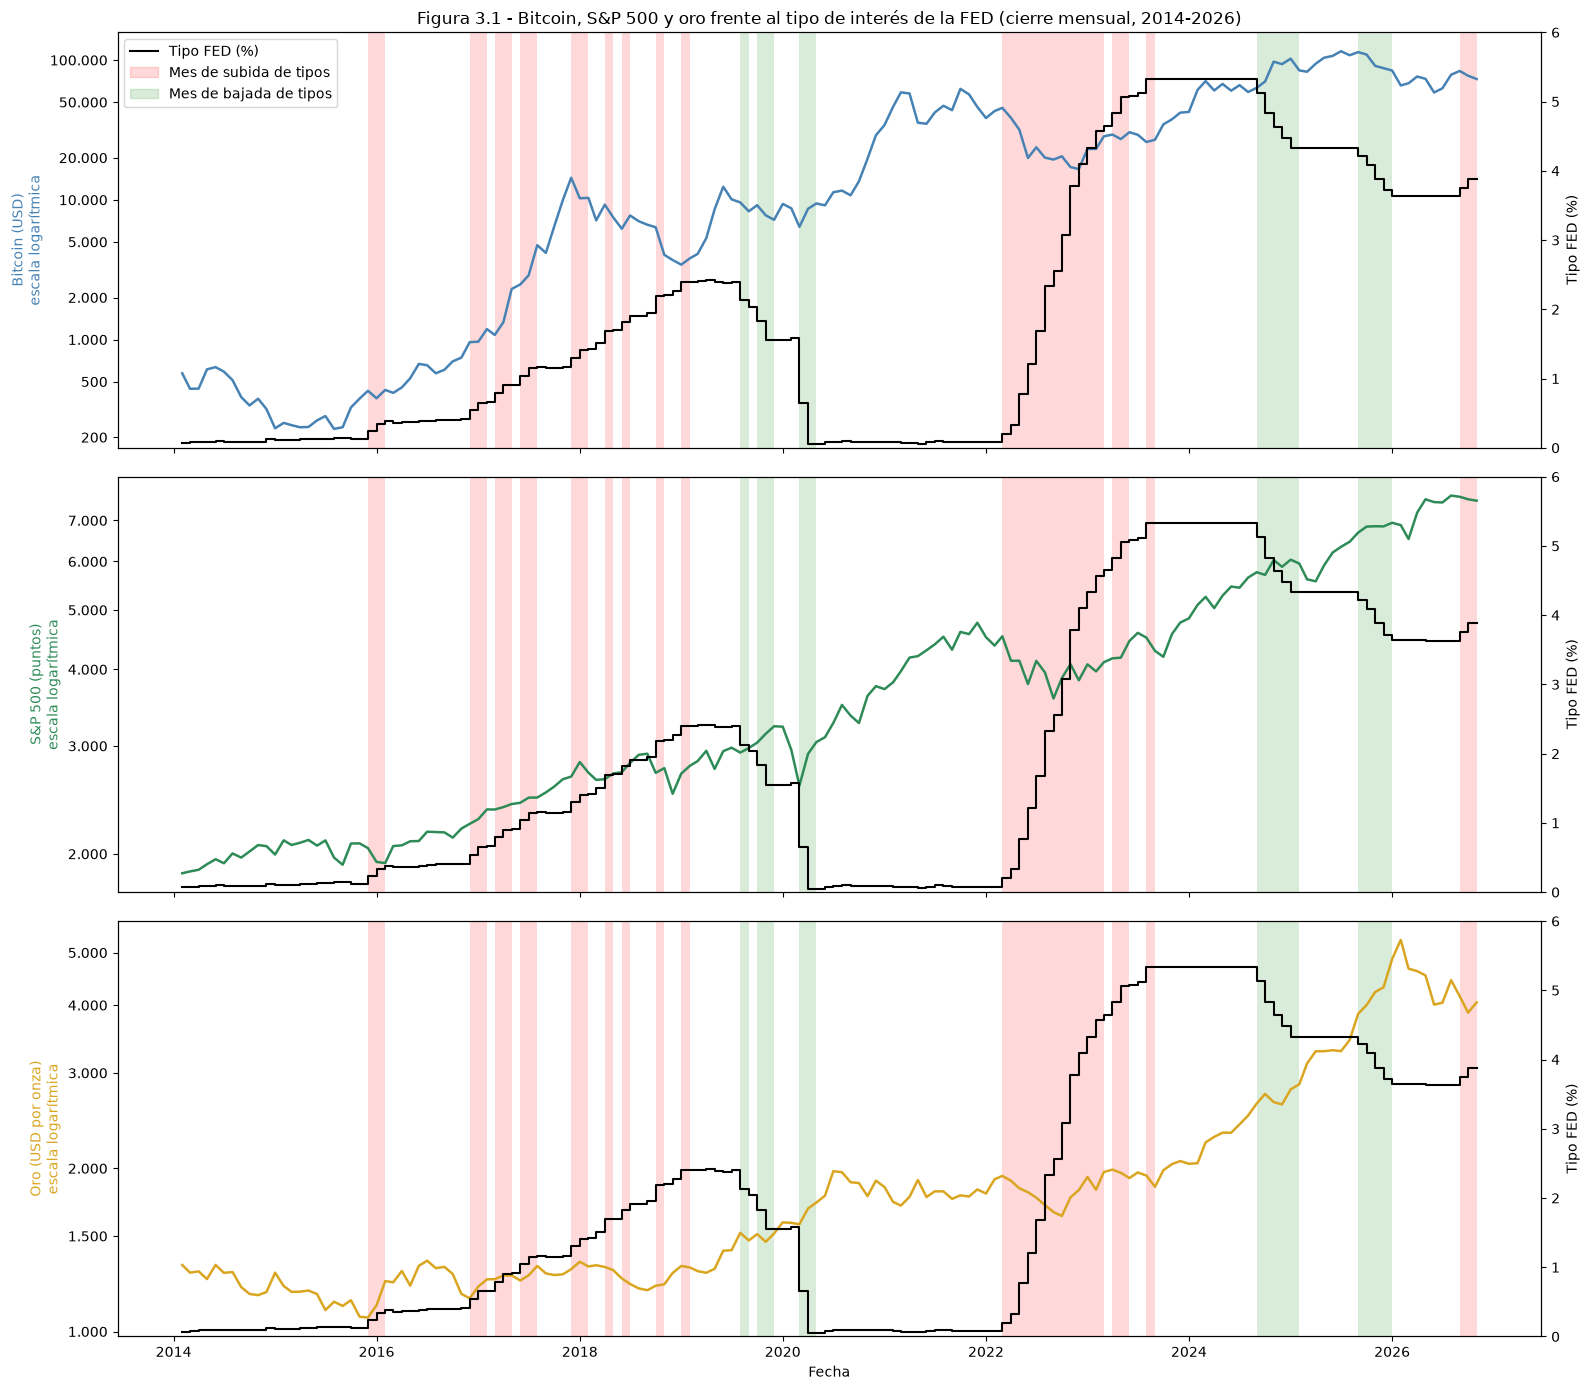

In [49]:
# Figura 3.1: cierre mensual de cada activo (eje izquierdo) frente al tipo de la FED (eje derecho).
# Fondo rojo = meses de subida de tipos; fondo verde = meses de bajada.

activos_h3 = {
    "bitcoin": ("Bitcoin (USD)", "steelblue"),
    "sp500": ("S&P 500 (puntos)", "seagreen"),
    "oro": ("Oro (USD por onza)", "goldenrod")
}
marcas_eje = {
    "bitcoin": [200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000],
    "sp500": [2000, 3000, 4000, 5000, 6000, 7000],
    "oro": [1000, 1500, 2000, 3000, 4000, 5000]
}

fig, ejes = plt.subplots(3, 1, figsize=(16, 14), sharex=True)
fechas = df_h3.index.to_timestamp()

for ax1, (activo, (nombre, color)) in zip(ejes, activos_h3.items()):
    # Eje izquierdo: precio del activo (escala logarítmica, con separador de miles ".")
    ax1.plot(fechas, df_h3[activo], color=color, linewidth=1.8)
    ax1.set_yscale("log")
    ax1.set_yticks(marcas_eje[activo])
    ax1.set_yticklabels([f"{m:,}".replace(",", ".") for m in marcas_eje[activo]])
    ax1.minorticks_off()
    ax1.set_ylabel(f"{nombre}\nescala logarítmica", color=color)

    # Eje derecho: tipo de la FED (%), en escalones porque cambia de mes en mes
    ax2 = ax1.twinx()
    ax2.step(fechas, df_h3["tipo_fed"], where="post", color="black", linewidth=1.5)
    ax2.set_ylim(0, 6)
    ax2.set_ylabel("Tipo FED (%)")
    ax2.grid(False)

    # Sombreado de cada mes de subida o bajada de tipos
    for periodo, fase in df_h3["fase_fed"].items():
        if fase != "Estable":
            ax1.axvspan(periodo.start_time, periodo.end_time,
                        color="red" if fase == "Subida" else "green", alpha=0.15, linewidth=0)

# Leyenda común
leyenda = [plt.Line2D([], [], color="black", label="Tipo FED (%)"),
           plt.Rectangle((0, 0), 1, 1, color="red", alpha=0.15, label="Mes de subida de tipos"),
           plt.Rectangle((0, 0), 1, 1, color="green", alpha=0.15, label="Mes de bajada de tipos")]
ejes[0].legend(handles=leyenda, loc="upper left")

ejes[0].set_title("Figura 3.1 - Bitcoin, S&P 500 y oro frente al tipo de interés de la FED (cierre mensual, 2014-2026)")
ejes[-1].set_xlabel("Fecha")
plt.tight_layout()
plt.show()

***Rentabilidad de cada activo por año y movimientos de la FED***

In [50]:
# Tabla resumen H3 por año: meses de subida y bajada, tipo al empezar y al acabar el año,
# y rentabilidad anual (%) de cada activo (se encadenan las rentabilidades mensuales).
# 2014 empieza en febrero (enero no tiene mes anterior) y 2026 llega hasta noviembre.

resumen_h3_anual = df_h3.groupby(df_h3.index.year).agg(
    subidas=("fase_fed", lambda f: (f == "Subida").sum()),
    bajadas=("fase_fed", lambda f: (f == "Bajada").sum()),
    tipo_inicio=("tipo_fed", "first"),
    tipo_fin=("tipo_fed", "last"),
    bitcoin=("rent_bitcoin", lambda r: ((1 + r / 100).prod() - 1) * 100),
    sp500=("rent_sp500", lambda r: ((1 + r / 100).prod() - 1) * 100),
    oro=("rent_oro", lambda r: ((1 + r / 100).prod() - 1) * 100)
).round(2)
resumen_h3_anual.index.name = "año"
resumen_h3_anual

,subidas,bajadas,tipo_inicio,tipo_fin,bitcoin,sp500,oro
año,,,,,,,
2014,0,0,0.07,0.12,-66.11,15.51,-4.95
2015,1,0,0.11,0.24,35.14,-0.73,-10.32
2016,2,0,0.34,0.54,123.01,9.54,8.54
2017,6,0,0.65,1.30,1400.72,19.43,13.20
2018,4,0,1.41,2.27,-74.23,-6.24,-1.59
2019,1,3,2.40,1.55,94.01,28.87,18.29
2020,0,2,1.55,0.09,302.26,16.26,25.10
2021,0,0,0.09,0.08,59.64,26.89,-3.67
2022,10,0,0.08,4.10,-64.06,-19.44,-0.28


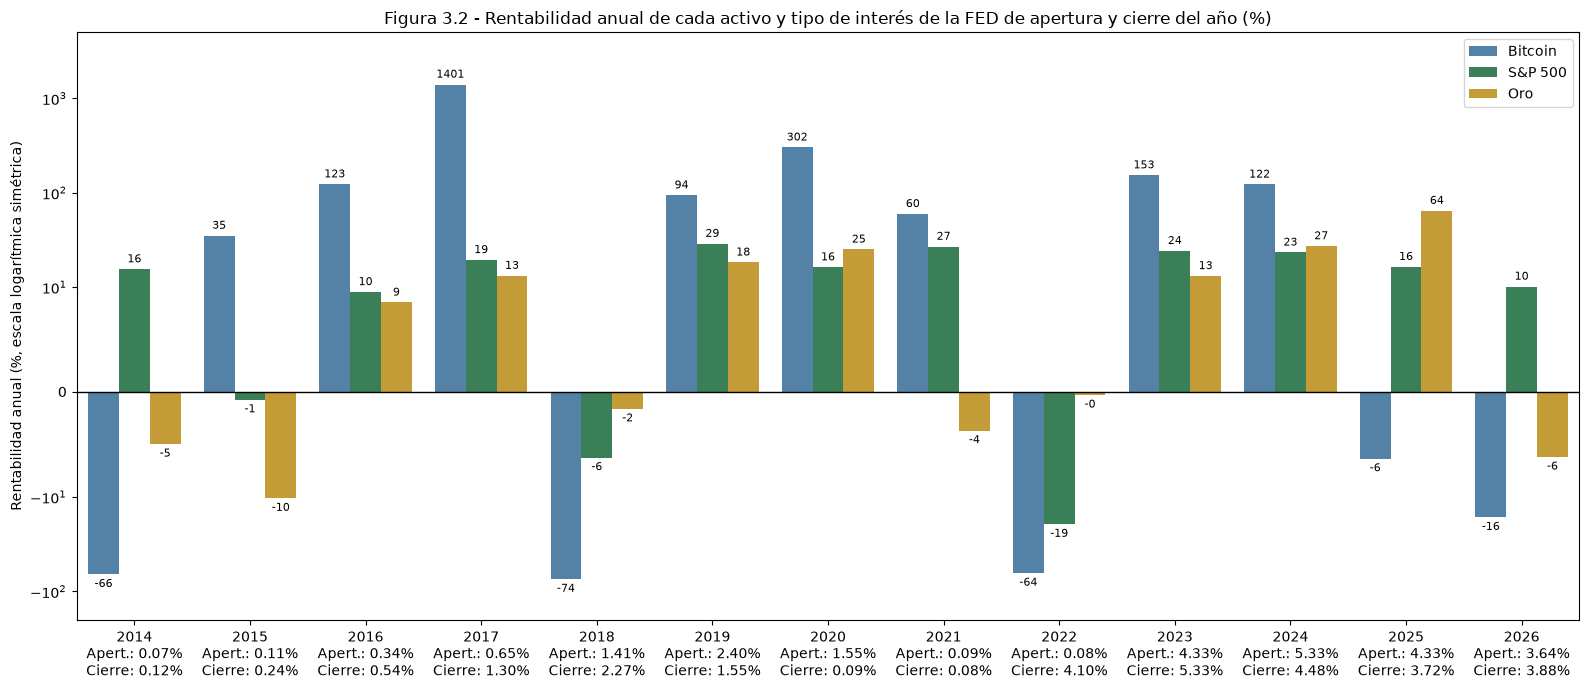

In [54]:
# Figura 3.2: rentabilidad anual de cada activo, con el tipo de interés de la FED al inicio y al cierre de cada año.

etiquetas_h3 = [f"{fila.Index}\nApert.: {fila.tipo_inicio:.2f}%\nCierre: {fila.tipo_fin:.2f}%" for fila in resumen_h3_anual.itertuples()]

h3_anual_largo = (resumen_h3_anual[["bitcoin", "sp500", "oro"]]
                  .rename(columns={"bitcoin": "Bitcoin", "sp500": "S&P 500", "oro": "Oro"})
                  .set_axis(etiquetas_h3)
                  .rename_axis("año").reset_index()
                  .melt(id_vars="año", var_name="activo", value_name="rentabilidad"))

plt.figure(figsize=(16, 7))
ax = sns.barplot(data=h3_anual_largo, x="año", y="rentabilidad", hue="activo",
                 hue_order=["Bitcoin", "S&P 500", "Oro"],
                 palette={"Bitcoin": "steelblue", "S&P 500": "seagreen", "Oro": "goldenrod"})

# El bitcoin llega a más de +1.000 %: escala simétrica logarítmica para que se vean también el S&P 500 y el oro.
ax.set_yscale("symlog", linthresh=10)
ax.set_ylim(-200, 5000)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.0f", padding=3, fontsize=8)

plt.axhline(0, color="black", linewidth=1)
plt.title("Figura 3.2 - Rentabilidad anual de cada activo y tipo de interés de la FED de apertura y cierre del año (%)")
plt.ylabel("Rentabilidad anual (%, escala logarítmica simétrica)")
plt.xlabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()

**LA HIPÓTESIS 3 SE CONFIRMA SOLO EN PARTE:**

- En los ciclos de subidas fuertes (2018 y 2022) el bitcoin cayó con la bolsa, pero mucho más: -74 % y -64 %, frente a -6 % y -19 % del S&P 500.
- Sin embargo, en otros años de subidas (2017 y 2023) el bitcoin se disparó (+1.401 % y +153 %): las subidas de tipos no siempre lo hunden.
- En los años de bajadas de tipos el bitcoin subió con fuerza (2019, 2020 y 2024), salvo en 2025 (-6 %).
- Cuando se mueve en la misma dirección que la bolsa, su reacción es mucho más intensa. Los tipos influyen, pero pesan más otros factores propios del bitcoin. 

-----------------------------------------------------------------------------------------------------------------------------------------------------

## **4.- CONCLUSIONES**

-----------------------------------------------------------------------------------------------------------------------------------------------------



| Hipótesis | Dato clave | ¿Se cumple? |
|---|---|---|
| H1 – Crisis | El bitcoin cayó en 7 de 9 crisis; media -20,2 % (S&P 500 -14,7 %, oro +0,8 %) | Sí |
| H2 – Comparativa | Correlación diaria con el S&P 500: 0,12 / con el oro: 0,04 | Sí, de forma débil |
| H3 – Tipos de la FED | Cae en los ciclos de subidas fuertes (2018: -74 %; 2022: -64 %), pero no de forma sistemática | Parcialmente |

### **CONCLUSIÓN: EL BITCOIN NO ES UN ACTIVO REFUGIO.**

- En las crisis cayó con la bolsa, y más que ella (H1).
- Se mueve más parecido a la renta variable que al oro, aunque su relación diaria con ambos es débil (H2).
- Reacciona a la política de la FED como un activo de riesgo en los ciclos de subidas fuertes, pero de forma irregular (H3).

**El bitcoin se comporta como un activo de riesgo de alta volatilidad, no como el "oro digital".**